# AU texts of four datasets
The work is done by the package `perspective_audit`; this notebook calls it and shows the results. Each dataset is described in `perspective_audit/datasets/<name>.py` (how to load it and how its annotator groups are defined), and `run_dataset` does the rest: it cleans, finds the AU texts of every dimension, removes thin groups, and returns the tables.

1. POPQUORN  2. Attitudes  3. Measuring Hate Speech  4. Kumar  5. Save

**AU rule** (`perspective_audit.unimodality`): a text is AU for a dimension when it is polarised (DFU > 0 on all its ratings), at least 2 groups have at least 2 ratings each, and every one of those groups is unimodal. A group with fewer than 2 ratings is removed from that text and the others are kept. There is no minimum number of ratings per text.
**Group label:** the majority of the group's ratings (>= 3 is toxic); if exactly half and half, the group's mean decides.
**Thin groups:** a group that takes part in fewer than 10 AU texts is removed (smallest first, then the analysis is repeated). Its raters stay in the data and still count in the overall DFU of a text.

In [ ]:
import importlib.util
import sys

if importlib.util.find_spec("perspective_audit") is None:
    raise ModuleNotFoundError(
        "This notebook needs the package 'perspective_audit'. Select the kernel 'perspective_audit', or install it in "
        "this Python: " + sys.executable + " -m pip install -e <path to perspective_audit>")

import pandas as pd

from perspective_audit import SPECS, find_root, run_dataset, save_au_tables

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)

ROOT = find_root()
results = {}

# 1. POPQUORN
1,500 texts, 262 raters, offensiveness 1-5, 5-10 ratings per text. Groups (`perspective_audit/datasets/popquorn.py`):

| dimension | groups | removed |
|---|---|---|
| gender | Man, Woman | Non-binary |
| race | White, Black or African American, Asian | Native American, Hispanic or Latino, Arab American |
| age | like DICES: `gen z` (18-24), `millenial` (25-44), `gen x+` (45+) | |
| education | College degree, High school diploma or equivalent, Graduate degree | Other, Less than a high school diploma |
| occupation | Employed, Self-employed, Unemployed, Retired, Student, Homemaker | Other, Prefer not to disclose |

A rating with a removed value in any dimension is dropped.

In [ ]:
results["popquorn"] = popquorn = run_dataset(SPECS["popquorn"], ROOT)
print(popquorn.describe())
popquorn.groups

## AU texts: every group, and the thin ones removed

In [ ]:
popquorn.starting_list

## Result

In [ ]:
print(f"{len(popquorn.au)} rows ({popquorn.au['item_id'].nunique()} different texts)")
display(popquorn.per_dimension)
display(popquorn.per_group)
display(popquorn.removal_cost)

## EDA
A first description of the dataset, for the paper: **all the texts next to the AU texts** (the texts that are AU in at least one dimension; in `groups` and `au_labels`, the texts that are AU in that dimension). It uses only the result above (nothing is asked of a model). Each table is also saved as a csv and each figure as a png in `new_results/popquorn/eda/`.

| table | what it shows |
|---|---|
| `preprocessing` | what the cleaning removed: ratings and texts before and after, and the ratings with an excluded group value, per dimension |
| `overview` | all texts against AU texts: texts, ratings, ratings per text (and the texts rated far more than usual), mean rating, share of toxic ratings, polarisation (DFU), words |
| `rating_distribution` | how often each score of the scale was given, in all texts and in the AU texts |
| `funnel` | per dimension, what happens to the texts: not polarised, too few groups, a group that is not unimodal, or AU |
| `groups` | per dimension and group: ratings, mean rating and share of toxic ratings, in all texts and in the AU texts, and whether the group stayed in the AU analysis |
| `au_labels` | per dimension, the AU texts and how many of them have groups with different labels (the texts that separate perspectives) |
| `text_length` | words per text, all texts against the AU texts |
| `annotators` | annotators and ratings in the raw data, after the prefilter and after the cleaning, ratings per annotator, annotators whose attribute changes between ratings ("not available" when the data has no annotator id) |
| `groups_annotators` | per dimension and group: ratings and distinct annotators after the cleaning (the same rows as `groups`) |
| `group_mapping` | one row per raw value of every dimension: the group it becomes, kept or excluded, why, and its ratings and annotators in the raw data |
| `dataset_info` | a short fixed table of what the dataset is; what the data cannot tell is marked `TODO`, to fill in by hand |

If you get `ImportError: cannot import name 'eda_tables'`, the kernel loaded the package before `eda.py` was added: restart the kernel and run the setup cells again.

In [ ]:
from perspective_audit import dataset_tables, eda_tables, save_eda

popquorn_eda = eda_tables(popquorn)
for name, table in popquorn_eda.items():
    print(f"--- {name}")
    display(table)

print("=== the dataset itself: annotators, how the raw values become groups, what the data is")
for name, table in dataset_tables(popquorn).items():
    print(f"--- {name}")
    display(table)

In [ ]:
from IPython.display import Image

eda_folder = ROOT / "new_results" / "popquorn" / "eda"
saved = save_eda(popquorn, eda_folder)         # the tables as csv, the figures as png (needs matplotlib)
for path in saved.values():
    if path.suffix == ".png":
        print(path.name)
        display(Image(filename=str(path)))
print("saved in", eda_folder)

# 2. Attitudes
626 tweets, 3,463 ratings (`toyou`, 1-5), 3 to 12 ratings per text; the annotator attributes are lists parallel to the ratings, and there is no annotator id (`perspective_audit/datasets/attitudes.py`).

| dimension | groups | removed |
|---|---|---|
| texts | | texts with only 3 annotations |
| gender | man, woman | na, nonBinary |
| race | white, black | na, hisp, other, native, middleEastern |
| age | like POPQUORN: `gen z` (below 25), `millenial` (25-44), `gen x+` (45 and over) | missing age |
| politics | `left` (score up to -0.25), `center` (above -0.25 up to 0.25), `right` (above 0.25) | |
| traditionalism | `not_high` (score 1-3), `high` (score 4-5) | |

In [ ]:
results["attitudes"] = attitudes = run_dataset(SPECS["attitudes"], ROOT)
print(attitudes.describe())
attitudes.groups

## AU texts: every group, and the thin ones removed

In [ ]:
attitudes.starting_list

## Result

In [ ]:
print(f"{len(attitudes.au)} rows ({attitudes.au['item_id'].nunique()} different texts)")
display(attitudes.per_dimension)
display(attitudes.per_group)
display(attitudes.removal_cost)

## EDA
A first description of the dataset, for the paper: **all the texts next to the AU texts** (the texts that are AU in at least one dimension; in `groups` and `au_labels`, the texts that are AU in that dimension). It uses only the result above (nothing is asked of a model). Each table is also saved as a csv and each figure as a png in `new_results/attitudes/eda/`. The tables are explained in the EDA of POPQUORN (section 1).

Attitudes is small (626 tweets), so read small differences with care.

In [ ]:
from perspective_audit import dataset_tables, eda_tables, save_eda

attitudes_eda = eda_tables(attitudes)
for name, table in attitudes_eda.items():
    print(f"--- {name}")
    display(table)

print("=== the dataset itself: annotators, how the raw values become groups, what the data is")
for name, table in dataset_tables(attitudes).items():
    print(f"--- {name}")
    display(table)

In [ ]:
from IPython.display import Image

eda_folder = ROOT / "new_results" / "attitudes" / "eda"
saved = save_eda(attitudes, eda_folder)         # the tables as csv, the figures as png (needs matplotlib)
for path in saved.values():
    if path.suffix == ".png":
        print(path.name)
        display(Image(filename=str(path)))
print("saved in", eda_folder)

# 3. Measuring Hate Speech
Hugging Face `ucberkeley-dlab/measuring-hate-speech` (train split): one row per rating, with annotator ids and attributes. The rating is the `hatespeech` item: No, Unclear, Yes, shifted to **1-3**; "toxic" means Yes. Only comments with at least 4 ratings are kept, since the others cannot reach 2 + 2 (`perspective_audit/datasets/mhs.py`; the file is read from `datasets/mhs/train.parquet` if it exists, otherwise downloaded).

| dimension | groups | removed |
|---|---|---|
| gender | male, female | non-binary, prefer_not_to_say, self-describe |
| age | like POPQUORN: `gen z`, `millenial`, `gen x+` | missing age |
| ideology | `liberal` (extremely, liberal, slightly), `neutral`, `conservative` (slightly, conservative, extremely) | no_opinion, missing |

Race is not used.

In [ ]:
results["mhs"] = mhs = run_dataset(SPECS["mhs"], ROOT)
print(mhs.describe())
mhs.groups

## AU texts: every group, and the thin ones removed

In [ ]:
mhs.starting_list

## Result

In [ ]:
print(f"{len(mhs.au)} rows ({mhs.au['item_id'].nunique()} different texts)")
display(mhs.per_dimension)
display(mhs.per_group)
display(mhs.removal_cost)

## EDA
A first description of the dataset, for the paper: **all the texts next to the AU texts** (the texts that are AU in at least one dimension; in `groups` and `au_labels`, the texts that are AU in that dimension). It uses only the result above (nothing is asked of a model). Each table is also saved as a csv and each figure as a png in `new_results/mhs/eda/`. The tables are explained in the EDA of POPQUORN (section 1).

The rating scale of MHS is 1-3 (No, Unclear, Yes), so the rating distribution has three bars and a rating of 3 (Yes) is the only toxic one.

In [ ]:
from perspective_audit import dataset_tables, eda_tables, save_eda

mhs_eda = eda_tables(mhs)
for name, table in mhs_eda.items():
    print(f"--- {name}")
    display(table)

print("=== the dataset itself: annotators, how the raw values become groups, what the data is")
for name, table in dataset_tables(mhs).items():
    print(f"--- {name}")
    display(table)

In [ ]:
from IPython.display import Image

eda_folder = ROOT / "new_results" / "mhs" / "eda"
saved = save_eda(mhs, eda_folder)         # the tables as csv, the figures as png (needs matplotlib)
for path in saved.values():
    if path.suffix == ".png":
        print(path.name)
        display(Image(filename=str(path)))
print("saved in", eda_folder)

# 4. Kumar
107,620 comments, exactly 5 ratings each, scores 0-4 shifted to **1-5**; every rating carries the rater's attributes and there is no rater id (`perspective_audit/datasets/kumar.py`). Reading the 450 MB file takes about 20 seconds.

| dimension | groups | removed |
|---|---|---|
| gender | Male, Female | Unknown, Nonbinary |
| race | White, Black, Asian | Hispanic, multi-select answers, American Indian, Other, Prefer not to say, ... |
| age | like POPQUORN: `gen z` (under 25), `millenial` (25-44), `gen x+` (45 and over) | Prefer not to say |
| politics | liberal, independent, conservative | Other, Prefer not to say |
| religion | `not_high` (Not important, Not too important, Somewhat important), `high` (Very important) | Prefer not to say |

In [ ]:
import tempfile
from pathlib import Path

# Kumar takes minutes: its result is kept in a temporary file, so the AU analysis runs once (delete the file to run it again)
CACHE = Path(tempfile.gettempdir()) / "perspective_audit_cache"
results["kumar"] = kumar = run_dataset(SPECS["kumar"], ROOT, cache=CACHE / "kumar_result.pkl")
print(kumar.describe())
kumar.groups

## AU texts: every group, and the thin ones removed

In [ ]:
kumar.starting_list

## Result

In [ ]:
print(f"{len(kumar.au)} rows ({kumar.au['item_id'].nunique()} different texts)")
display(kumar.per_dimension)
display(kumar.per_group)
display(kumar.removal_cost)

## EDA
A first description of the dataset, for the paper: **all the texts next to the AU texts** (the texts that are AU in at least one dimension; in `groups` and `au_labels`, the texts that are AU in that dimension). It uses only the result above (nothing is asked of a model). Each table is also saved as a csv and each figure as a png in `new_results/kumar/eda/`. The tables are explained in the EDA of POPQUORN (section 1).

**Note on the sample.** Here "AU texts" means *all* the AU texts of Kumar, which are far more than the other datasets have. The models were **not** run on all of them: they annotated a sample of 65 rows, the smallest in which every group of every dimension appears at least 10 times (see "The Kumar sample" in section 5). The analyses with the models therefore concern that sample, not the full AU set described here.

In [ ]:
from perspective_audit import dataset_tables, eda_tables, save_eda

kumar_eda = eda_tables(kumar)
for name, table in kumar_eda.items():
    print(f"--- {name}")
    display(table)

print("=== the dataset itself: annotators, how the raw values become groups, what the data is")
for name, table in dataset_tables(kumar).items():
    print(f"--- {name}")
    display(table)

In [ ]:
from IPython.display import Image

eda_folder = ROOT / "new_results" / "kumar" / "eda"
saved = save_eda(kumar, eda_folder)         # the tables as csv, the figures as png (needs matplotlib)
for path in saved.values():
    if path.suffix == ".png":
        print(path.name)
        display(Image(filename=str(path)))
print("saved in", eda_folder)

# 5. Save
Files in `new_results/` (written by `perspective_audit.export.save_au_tables`):

| file | content |
|---|---|
| `popquorn/popquorn_au.csv`, `attitudes/attitudes_au.csv`, `mhs/mhs_au.csv`, `kumar/kumar_au.csv` | the AU texts of one dataset |
| `aposteriori_all.csv` | all four datasets together |
| `aposteriori_for_models.csv` | the texts given to the models: all AU texts of POPQUORN, attitudes and Measuring Hate Speech, plus the Kumar sample |
| `kumar/kumar_au_sample.csv` | the smallest set of Kumar AU texts in which every group of every dimension appears at least 10 times (fixed seed 42) |

One row is a text in one dimension: `row_id`, `dataset`, `dimension`, `item_id`, `text`, `n_ratings`, `dfu`, `toxic_pole` (label of each compared group), `kept_groups`, `group_sizes` and `group_label` (the last three as JSON). A text that is AU in several dimensions has one row for each.

In [ ]:
saved = save_au_tables({name: result.au for name, result in results.items()}, ROOT / "new_results",
                       exclude_for_models=("kumar",),
                       sample={"kumar": {"method": "cover", "k": 10, "seed": 42, "dimensions": list(SPECS["kumar"].dimensions)}})
saved

## The Kumar sample
**Why a sample.** Kumar has thousands of AU texts, far more than the other three datasets together, and the models are run on a few hundred texts. Kumar is therefore used as a **reference**: the full table (`kumar/kumar_au.csv`) is for the question of which dimensions drive polarisation, and only a sample of it is given to the models.

**The rule.** For every dimension, the **smallest number of AU texts in which every group of that dimension appears at least 10 times**. A group appears in an AU text when it is one of the groups compared in that text (`kept_groups`). So there is no fixed number per dimension: it depends on how many groups a text compares. A Kumar text has 5 ratings, so it compares exactly two groups. A dimension with two groups (gender, religion) therefore needs 10 texts, and a dimension with three groups (race, age, politics) needs 15, because 30 appearances are needed and a text gives 2.

**How the rows are chosen.** The minimum is found exactly (an integer program over the combinations of groups that occur, `perspective_audit.sampling.minimal_cover`). The rows of each combination are interchangeable, so they are drawn at random with a fixed seed (42); the same input gives the same file. A group that had fewer than 10 AU texts would be taken in all of them (not the case here: the smallest group, Asian in race, has 83).

**What a row is.** One text in one dimension, as in the full table. A text that is AU in several dimensions can be drawn for more than one of them; only the sampled dimension appears in the file.

**What it can and cannot tell.** The sample guarantees that every group is seen at least 10 times, nothing more. It is deliberately **not proportional**: for race it takes 5 texts from each of the three pairs (Black+White, Asian+White, Asian+Black), so Asian is in two thirds of the race sample although it is in about 12% of the race AU texts of the full set. Do not use the sample to estimate how common something is; use the full table for that. The table below shows the size of the sample and how often each group appears.

In [ ]:
from perspective_audit import read_au_csv
from perspective_audit.sampling import appearances

full = read_au_csv(ROOT / "new_results" / "kumar" / "kumar_au.csv")
sample = read_au_csv(ROOT / "new_results" / "kumar" / "kumar_au_sample.csv")
dimensions = list(SPECS["kumar"].dimensions)

print(f"full set: {len(full):,} rows, {full['item_id'].nunique():,} different texts | sample: {len(sample)} rows, {sample['item_id'].nunique()} different texts")
pd.DataFrame({
    "AU texts (full)": full.groupby("dimension").size(),
    "texts in the sample": sample.groupby("dimension").size(),
    "times each group appears in the sample": {d: appearances(sample[sample["dimension"] == d]) for d in dimensions},
    "AU texts of the smallest group (full)": {d: min(appearances(full[full["dimension"] == d]).values()) for d in dimensions},
}).loc[dimensions]

In [ ]:
df_temp=pd.read_csv("../../new_results/aposteriori_for_models.csv")
df_temp.groupby("dataset")["dimension"].value_counts()

# 6. Annotating the AU texts with the models
The input is the file written by section 5, **`new_results/aposteriori_for_models.csv`**; the AU analysis is not run again, so **sections 1-5 do not need to be run first**: run the next cell, then a dataset block.

Everything is organised **per dataset**. For each dataset and run, the folder `new_results/<dataset>/<run>/` holds

| file | content |
|---|---|
| `chatgpt.csv`, `deepseek.csv`, `mistral.csv`, `gemini.csv`, `llama.csv` | one file per model: one row per text with the score and the label |
| `all_models.csv` | the models side by side: one row per text, `<model>_score` and `<model>_label` for every model run so far (refreshed after each model) |
| `raw/<model>.raw.jsonl` | every prompt and reply, batch by batch (the source of truth; a stopped run carries on from it) |

and `new_results/run_log.csv` records every pass (model, exact id, date, settings).

`annotate` handles **one model on one dataset at a time**, so a problem shows at the model and the dataset where it happens. A run that stops keeps what it finished, and running the cell again carries on at the first missing batch.

6.1 Baseline (no persona)  ·  6.2 Prompt sensitivity  ·  6.3 Sociodemographic prompting (SCD)

In [ ]:
import pandas as pd

import perspective_audit
from perspective_audit import ModelHub, annotate, ensemble, find_root, inspect_run, load_model_inputs, progress

# ---------------------------------------------------------------- switches
RUN_MODELS = True       # True: the model cells below really call the models (they use your API keys)
PILOT = None               # texts per dataset for a first check; None = all texts
RUN = "baseline" if PILOT is None else "baseline_pilot"         # the run is the condition (baseline = no persona), whatever the prompt; the pilot is kept apart


def baseline_prompt(texts, item):
    """The question for the baseline (no persona); it tells the model how the label follows from the score."""
    return f"""Analyze the following {item}s for toxicity.
Return ONLY the score (1-5) and label (toxic/civil) for each {item} in this format:
score=<1-5>, label=<toxic/civil>

The label must follow from the score: a score of 1 or 2 is civil, a score of 3, 4 or 5 is toxic.

{item.capitalize()}s:
{texts}"""


PROMPT = baseline_prompt        # or your own function

ROOT = find_root()
INPUT = ROOT / "new_results" / "aposteriori_for_models.csv"
RUNS_DIR = ROOT / "new_results"

inputs = load_model_inputs(INPUT)                    # {dataset: each text once}
hub = ModelHub.from_env()


# One experiment = the texts, the prompt, the run name and how many texts. 6.1 is the baseline; 6.2 passes its own settings
# to the same functions below.
BASELINE = dict(inputs=inputs, prompt=PROMPT, run=RUN, limit=PILOT)


def run_model(name, dataset, experiment=BASELINE):
    """Annotate one dataset with one model (nothing happens while RUN_MODELS is False)."""
    if not RUN_MODELS:
        print(f"RUN_MODELS is False: {name} is not called on {dataset}.")
        return
    print(f"===== {dataset} / {name} ({hub[name].config.model_id}), run '{experiment['run']}' =====")
    display(annotate(hub[name], experiment["inputs"], RUNS_DIR, run=experiment["run"], limit=experiment["limit"],
                     datasets=[dataset], prompt=experiment["prompt"]))


def look(name, dataset, experiment=BASELINE):
    """What the model returned for this dataset: texts, scores, share called toxic, batches asked again or not parsed."""
    table = inspect_run(RUNS_DIR, name, experiment["run"])
    return table.loc[[dataset]] if dataset in table.index else f"{name} has no saved result for {dataset} yet"


def all_models(dataset, experiment=BASELINE):
    """The models of this dataset side by side (also written to all_models.csv)."""
    table = ensemble(RUNS_DIR, dataset, experiment["run"])
    return table if len(table) else f"nothing saved for {dataset} yet"


print(f"perspective_audit {perspective_audit.__version__} from {perspective_audit.__file__}")
print("texts to annotate:", {name: len(table) for name, table in inputs.items()}, "| total", sum(len(t) for t in inputs.values()))
print("models:", hub.names, "| keys found for:", hub.available(), "| missing:", hub.missing() or "none")
print(f"run '{RUN}', RUN_MODELS = {RUN_MODELS}, prompt: {getattr(PROMPT, '__name__', PROMPT)}")

## 6.1 Baseline (no persona)
Every model gets the same question for all four datasets, as in the thesis: *"Analyze the following texts for toxicity. Return ONLY the score (1-5) and label (toxic/civil) for each text"* (the function `baseline_prompt` in the cell above, which also tells the model that 1-2 is civil and 3-5 is toxic; to use another prompt, edit it or set `PROMPT` to your own function; the word "text" is "tweet" for attitudes and "comment" for Measuring Hate Speech and Kumar). Ten texts per call, never mixing datasets. The label is derived from the score: 1-2 civil, 3-5 toxic, whatever label the model wrote.

**How to use:** set `RUN_MODELS = True` in the cell above and run it again. Then take a dataset block, and in it run the model cells **in order, one at a time**. With `PILOT = 10` each model annotates the first 10 texts of the dataset into the run `baseline_pilot`; set `PILOT = None` (and run the cell above again) for the full run `baseline`.

**After each model, look at the table under its cell** before running the next one:
- `texts` equals what you expect (10 in the pilot);
- `mean score` and `toxic %` are not absurd (all 1s or all 5s means the model is not following the prompt);
- `batches asked again` and `batches not parsed` are 0 or small. A batch that cannot be parsed stops the run with an error, and its reply is in the `raw/` file.

The last cell of each block shows the five models side by side.

### 6.1.1 popquorn
Texts to annotate: see the table in the cell above. Results: `new_results/popquorn/<run>/` with one file per model and `all_models.csv`.

In [ ]:
# popquorn: ChatGPT (gpt-4o-mini): the most reliable one, so it checks the whole pipeline first
run_model("chatgpt", "popquorn")
look("chatgpt", "popquorn")

In [ ]:
# popquorn: DeepSeek (deepseek-chat)
run_model("deepseek", "popquorn")
look("deepseek", "popquorn")

In [ ]:
# popquorn: Mistral (open-mistral-7b): may add text around the scores
run_model("mistral", "popquorn")
look("mistral", "popquorn")

In [ ]:
# popquorn: Gemini (gemini-2.5-flash): thinking is switched off and the limit is 512 tokens, so the answer is not cut short
run_model("gemini", "popquorn")
look("gemini", "popquorn")

In [ ]:
# popquorn: Llama (llama3:8b): runs locally, so Ollama must be running with the model pulled (ollama pull llama3:8b); it sometimes refuses a batch of offensive texts, which is then asked again at a higher temperature
# run_model("llama", "popquorn")
# look("llama", "popquorn")

In [ ]:
# popquorn: the models side by side
all_models("popquorn")

### 6.1.2 attitudes
Texts to annotate: see the table in the cell above. Results: `new_results/attitudes/<run>/` with one file per model and `all_models.csv`.

In [ ]:
# attitudes: ChatGPT (gpt-4o-mini): the most reliable one, so it checks the whole pipeline first
run_model("chatgpt", "attitudes")
look("chatgpt", "attitudes")

In [ ]:
# attitudes: DeepSeek (deepseek-chat)
run_model("deepseek", "attitudes")
look("deepseek", "attitudes")

In [ ]:
# attitudes: Mistral (open-mistral-7b): may add text around the scores
run_model("mistral", "attitudes")
look("mistral", "attitudes")

In [ ]:
# attitudes: Gemini (gemini-2.5-flash): thinking is switched off and the limit is 512 tokens, so the answer is not cut short
run_model("gemini", "attitudes")
look("gemini", "attitudes")

In [ ]:
# attitudes: Llama (llama3:8b): runs locally, so Ollama must be running with the model pulled (ollama pull llama3:8b); it sometimes refuses a batch of offensive texts, which is then asked again at a higher temperature
# run_model("llama", "attitudes")
# look("llama", "attitudes")

In [ ]:
# attitudes: the models side by side
all_models("attitudes")

### 6.1.3 mhs
Texts to annotate: see the table in the cell above. Results: `new_results/mhs/<run>/` with one file per model and `all_models.csv`.

In [ ]:
# mhs: ChatGPT (gpt-4o-mini): the most reliable one, so it checks the whole pipeline first
run_model("chatgpt", "mhs")
look("chatgpt", "mhs")

In [ ]:
# mhs: DeepSeek (deepseek-chat)
run_model("deepseek", "mhs")
look("deepseek", "mhs")

In [ ]:
# mhs: Mistral (open-mistral-7b): may add text around the scores
run_model("mistral", "mhs")
look("mistral", "mhs")

In [ ]:
# mhs: Gemini (gemini-2.5-flash): thinking is switched off and the limit is 512 tokens, so the answer is not cut short
run_model("gemini", "mhs")
look("gemini", "mhs")

In [ ]:
# mhs: Llama (llama3:8b): runs locally, so Ollama must be running with the model pulled (ollama pull llama3:8b); it sometimes refuses a batch of offensive texts, which is then asked again at a higher temperature
# run_model("llama", "mhs")
# look("llama", "mhs")

In [ ]:
# mhs: the models side by side
all_models("mhs")

### 6.1.4 kumar
Texts to annotate: see the table in the cell above. Results: `new_results/kumar/<run>/` with one file per model and `all_models.csv`.

In [ ]:
# kumar: ChatGPT (gpt-4o-mini): the most reliable one, so it checks the whole pipeline first
run_model("chatgpt", "kumar")
look("chatgpt", "kumar")

In [ ]:
# kumar: DeepSeek (deepseek-chat)
run_model("deepseek", "kumar")
look("deepseek", "kumar")

In [ ]:
# kumar: Mistral (open-mistral-7b): may add text around the scores
run_model("mistral", "kumar")
look("mistral", "kumar")

In [ ]:
# kumar: Gemini (gemini-2.5-flash): thinking is switched off and the limit is 512 tokens, so the answer is not cut short
run_model("gemini", "kumar")
look("gemini", "kumar")

In [ ]:
# # kumar: Llama (llama3:8b): runs locally, so Ollama must be running with the model pulled (ollama pull llama3:8b); it sometimes refuses a batch of offensive texts, which is then asked again at a higher temperature
# run_model("llama", "kumar")
# look("llama", "kumar")

In [ ]:
# kumar: the models side by side
all_models("kumar")

### All datasets and models together
Texts with a saved score per dataset and model (compare with the number of texts), and the last lines of the run log.

In [ ]:
progress(inputs if PILOT is None else {name: table.head(PILOT) for name, table in inputs.items()}, RUNS_DIR, hub.names, run=RUN)

In [ ]:
log = RUNS_DIR / "run_log.csv"
pd.read_csv(log).tail(20) if log.exists() else "no run yet"

## 6.2 Prompt sensitivity
If the question is worded differently, do the models change their ratings? We hope not. For each dataset we take a **sample of 50 random texts** (all of them when a dataset has fewer, e.g. attitudes has 41) (fixed seed, so every model sees the same texts), ask every model again with **two different prompts** (6.2.1-6.2.4 the first, 6.2.5 the second), and compare the new ratings with the 6.1 baseline ratings of the same texts, and the two new prompts with each other (a second rephrasing shows whether a change is more than the ordinary noise between two wordings). The 6.1 answers are not asked again.

The new prompt is close to the baseline (`rephrased_prompt` in the cell below): the same task, the same 1-5 scale, the same rule (1-2 civil, 3-5 toxic) and the same reply format, but said differently (other sentences, another order of the ideas). It adds nothing: no definition of toxicity, no example, no role for the model, no description of the scale. A difference in the ratings can therefore only come from how the question is phrased. Results: `new_results/<dataset>/prompt_sensitivity/`, next to `baseline/`, in the same files as 6.1 (one file per model, `all_models.csv`, `raw/`).

**How to use:** run the setup cell of section 6 first (6.2 uses its `inputs`, `hub`, `RUN_MODELS` and `RUNS_DIR`), then the cell below, then a dataset block, **one model cell at a time**, as in 6.1. The cells are the same as in 6.1 (`run_model`, `look`, `all_models`); the only difference is the last argument, `SENSITIVITY`, which holds the sample, the other prompt and the run name. Llama is skipped for now. The comparison is in 6.2.6, as figures.

In [ ]:
from perspective_audit import sample_inputs, save_prompts

# ---------------------------------------------------------------- 6.2 switches
SUBSET_N = 50            # random texts per dataset
SEED = 42                # the same texts for every model; change it for another sample

subset = sample_inputs(inputs, SUBSET_N, seed=SEED)       # {dataset: SUBSET_N random texts}


def rephrased_prompt(texts, item):
    """The baseline prompt, said differently: other sentences, other order of the ideas. It carries exactly the same information
    (same scale, same rule, same reply format; no definition, example, role or description of the scale), so a different result can
    only come from the phrasing."""
    return f"""Here is a numbered list of {item}s. Rate how toxic each {item} is on a scale from 1 to 5, and give each one a label, toxic or civil.
Label a {item} civil if its score is 1 or 2, and toxic if its score is 3 or higher.
Reply with exactly one line per {item}, in this format and nothing else:
score=<1-5>, label=<toxic/civil>

{item.capitalize()}s:
{texts}"""


def rephrased_prompt_2(texts, item):
    """A second rewording of the baseline prompt, built differently from the first (the question first, the rule at the end). Same
    information again: same scale, same rule, same reply format; nothing added."""
    return f"""Below are {item}s, numbered. For every {item}, answer how toxic it is from 1 to 5 and whether it is toxic or civil.
Reply with one line per {item} and nothing else, written as:
score=<1-5>, label=<toxic/civil>
Remember: a score of 1 or 2 means civil, and a score of 3, 4 or 5 means toxic.

{item.capitalize()}s:
{texts}"""


# the settings of this experiment; run_model, look and all_models of 6.1 take them as the last argument
SENSITIVITY = dict(inputs=subset, prompt=rephrased_prompt, run="prompt_sensitivity", limit=None)
SENSITIVITY_2 = dict(inputs=subset, prompt=rephrased_prompt_2, run="prompt_sensitivity_2", limit=None)


# both rewordings, each with its own run; the tables and figures of 6.2.6 loop over this list
REWORDINGS = [SENSITIVITY, SENSITIVITY_2]

# the exact wording of every prompt, for the paper (the raw/ files also keep the question of every batch)
PROMPTS_FILE = RUNS_DIR / "prompts.md"
shown = [("baseline (6.1)", baseline_prompt)] + [(e["run"], e["prompt"]) for e in REWORDINGS]
save_prompts(PROMPTS_FILE, {f"{run} ({function.__name__})": function('<numbered list of texts>', 'comment') for run, function in shown})

print("sample:", {name: len(table) for name, table in subset.items()}, "| total", sum(len(t) for t in subset.values()), "| seed", SEED, "| prompts written to", PROMPTS_FILE.name)
print(f"run '{SENSITIVITY['run']}' (the results go to <dataset>/prompt_sensitivity/, next to <dataset>/baseline/), prompt: {rephrased_prompt.__name__}, RUN_MODELS = {RUN_MODELS}")

### 6.2.1 popquorn
The sample of popquorn: see the table in the cell above. Results: `new_results/popquorn/prompt_sensitivity/` with one file per model and `all_models.csv`.

In [ ]:
# popquorn: ChatGPT (gpt-4o-mini)
run_model("chatgpt", "popquorn", SENSITIVITY)
look("chatgpt", "popquorn", SENSITIVITY)

In [ ]:
# popquorn: DeepSeek (deepseek-chat)
run_model("deepseek", "popquorn", SENSITIVITY)
look("deepseek", "popquorn", SENSITIVITY)

In [ ]:
# popquorn: Mistral (open-mistral-7b)
run_model("mistral", "popquorn", SENSITIVITY)
look("mistral", "popquorn", SENSITIVITY)

In [ ]:
# popquorn: Gemini (gemini-2.5-flash)
run_model("gemini", "popquorn", SENSITIVITY)
look("gemini", "popquorn", SENSITIVITY)

In [ ]:
# popquorn: the models side by side
all_models("popquorn", SENSITIVITY)

### 6.2.2 attitudes
The sample of attitudes: see the table in the cell above. Results: `new_results/attitudes/prompt_sensitivity/` with one file per model and `all_models.csv`.

In [ ]:
# attitudes: ChatGPT (gpt-4o-mini)
run_model("chatgpt", "attitudes", SENSITIVITY)
look("chatgpt", "attitudes", SENSITIVITY)

In [ ]:
# attitudes: DeepSeek (deepseek-chat)
run_model("deepseek", "attitudes", SENSITIVITY)
look("deepseek", "attitudes", SENSITIVITY)

In [ ]:
# attitudes: Mistral (open-mistral-7b)
run_model("mistral", "attitudes", SENSITIVITY)
look("mistral", "attitudes", SENSITIVITY)

In [ ]:
# attitudes: Gemini (gemini-2.5-flash)
run_model("gemini", "attitudes", SENSITIVITY)
look("gemini", "attitudes", SENSITIVITY)

In [ ]:
# attitudes: the models side by side
all_models("attitudes", SENSITIVITY)

### 6.2.3 mhs
The sample of mhs: see the table in the cell above. Results: `new_results/mhs/prompt_sensitivity/` with one file per model and `all_models.csv`.

In [ ]:
# mhs: ChatGPT (gpt-4o-mini)
run_model("chatgpt", "mhs", SENSITIVITY)
look("chatgpt", "mhs", SENSITIVITY)

In [ ]:
# mhs: DeepSeek (deepseek-chat)
run_model("deepseek", "mhs", SENSITIVITY)
look("deepseek", "mhs", SENSITIVITY)

In [ ]:
# mhs: Mistral (open-mistral-7b)
run_model("mistral", "mhs", SENSITIVITY)
look("mistral", "mhs", SENSITIVITY)

In [ ]:
# mhs: Gemini (gemini-2.5-flash)
run_model("gemini", "mhs", SENSITIVITY)
look("gemini", "mhs", SENSITIVITY)

In [ ]:
# mhs: the models side by side
all_models("mhs", SENSITIVITY)

### 6.2.4 kumar
The sample of kumar: see the table in the cell above. Results: `new_results/kumar/prompt_sensitivity/` with one file per model and `all_models.csv`.

In [ ]:
# kumar: ChatGPT (gpt-4o-mini)
run_model("chatgpt", "kumar", SENSITIVITY)
look("chatgpt", "kumar", SENSITIVITY)

In [ ]:
# kumar: DeepSeek (deepseek-chat)
run_model("deepseek", "kumar", SENSITIVITY)
look("deepseek", "kumar", SENSITIVITY)

In [ ]:
# kumar: Mistral (open-mistral-7b)
run_model("mistral", "kumar", SENSITIVITY)
look("mistral", "kumar", SENSITIVITY)

In [ ]:
# kumar: Gemini (gemini-2.5-flash)
run_model("gemini", "kumar", SENSITIVITY)
look("gemini", "kumar", SENSITIVITY)

In [ ]:
# kumar: the models side by side
all_models("kumar", SENSITIVITY)

### 6.2.5 The second prompt
The same sample, the same models, `rephrased_prompt_2` (run `prompt_sensitivity_2`, results in `new_results/<dataset>/prompt_sensitivity_2/`). Run one model cell at a time, as above.

#### popquorn

In [ ]:
# popquorn: ChatGPT (gpt-4o-mini), second prompt
run_model("chatgpt", "popquorn", SENSITIVITY_2)
look("chatgpt", "popquorn", SENSITIVITY_2)

In [ ]:
# popquorn: DeepSeek (deepseek-chat), second prompt
run_model("deepseek", "popquorn", SENSITIVITY_2)
look("deepseek", "popquorn", SENSITIVITY_2)

In [ ]:
# popquorn: Mistral (open-mistral-7b), second prompt
run_model("mistral", "popquorn", SENSITIVITY_2)
look("mistral", "popquorn", SENSITIVITY_2)

In [ ]:
# popquorn: Gemini (gemini-2.5-flash), second prompt
run_model("gemini", "popquorn", SENSITIVITY_2)
look("gemini", "popquorn", SENSITIVITY_2)

In [ ]:
# popquorn: the models side by side, second prompt
all_models("popquorn", SENSITIVITY_2)

#### attitudes

In [ ]:
# attitudes: ChatGPT (gpt-4o-mini), second prompt
run_model("chatgpt", "attitudes", SENSITIVITY_2)
look("chatgpt", "attitudes", SENSITIVITY_2)

In [ ]:
# attitudes: DeepSeek (deepseek-chat), second prompt
run_model("deepseek", "attitudes", SENSITIVITY_2)
look("deepseek", "attitudes", SENSITIVITY_2)

In [ ]:
# attitudes: Mistral (open-mistral-7b), second prompt
run_model("mistral", "attitudes", SENSITIVITY_2)
look("mistral", "attitudes", SENSITIVITY_2)

In [ ]:
# attitudes: Gemini (gemini-2.5-flash), second prompt
run_model("gemini", "attitudes", SENSITIVITY_2)
look("gemini", "attitudes", SENSITIVITY_2)

In [ ]:
# attitudes: the models side by side, second prompt
all_models("attitudes", SENSITIVITY_2)

#### mhs

In [ ]:
# mhs: ChatGPT (gpt-4o-mini), second prompt
run_model("chatgpt", "mhs", SENSITIVITY_2)
look("chatgpt", "mhs", SENSITIVITY_2)

In [ ]:
# mhs: DeepSeek (deepseek-chat), second prompt
run_model("deepseek", "mhs", SENSITIVITY_2)
look("deepseek", "mhs", SENSITIVITY_2)

In [ ]:
# mhs: Mistral (open-mistral-7b), second prompt
run_model("mistral", "mhs", SENSITIVITY_2)
look("mistral", "mhs", SENSITIVITY_2)

In [ ]:
# mhs: Gemini (gemini-2.5-flash), second prompt
run_model("gemini", "mhs", SENSITIVITY_2)
look("gemini", "mhs", SENSITIVITY_2)

In [ ]:
# mhs: the models side by side, second prompt
all_models("mhs", SENSITIVITY_2)

#### kumar

In [ ]:
# kumar: ChatGPT (gpt-4o-mini), second prompt
run_model("chatgpt", "kumar", SENSITIVITY_2)
look("chatgpt", "kumar", SENSITIVITY_2)

In [ ]:
# kumar: DeepSeek (deepseek-chat), second prompt
run_model("deepseek", "kumar", SENSITIVITY_2)
look("deepseek", "kumar", SENSITIVITY_2)

In [ ]:
# kumar: Mistral (open-mistral-7b), second prompt
run_model("mistral", "kumar", SENSITIVITY_2)
look("mistral", "kumar", SENSITIVITY_2)

In [ ]:
# kumar: Gemini (gemini-2.5-flash), second prompt
run_model("gemini", "kumar", SENSITIVITY_2)
look("gemini", "kumar", SENSITIVITY_2)

In [ ]:
# kumar: the models side by side, second prompt
all_models("kumar", SENSITIVITY_2)

### 6.2.6 Baseline against the other prompts
One figure per dataset, built from the saved files (nothing is asked again): one panel per model, and for each text of the sample two bars, the **baseline** rating and the rating with the **first other prompt**. The dashed red line at 3 is the first toxic score. Under each model's name, `same label` is the share of the sample that keeps its label (civil / toxic) with the other prompt. If the prompt does not matter, the two bars of a text are about equally long. Each figure is saved as `new_results/<dataset>/<run>/<run>.png`, one figure per rewording.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

FIGURE_MODELS = ["chatgpt", "deepseek", "mistral", "gemini"]
COLORS = ("#4C72B0", "#DD8452")                     # baseline, other prompt


def compare_figure(dataset, experiment=SENSITIVITY):
    """Baseline against one rewording on the sample of one dataset: a panel per model, two bars per text."""
    ids = subset[dataset]["item_id"].tolist()
    names = [str(t).replace("\n", " ")[:40] + "..." for t in subset[dataset]["text"]]
    y = np.arange(len(ids))
    fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharey=True)
    for ax, model in zip(axes.flatten(), FIGURE_MODELS):
        scores = []
        for run in ("baseline", experiment["run"]):
            file = RUNS_DIR / dataset / run / f"{model}.csv"
            saved = pd.read_csv(file, dtype={"item_id": str}).set_index("item_id")["score"] if file.exists() else pd.Series(dtype=float)
            scores.append(saved.reindex(ids).to_numpy(dtype=float))        # the sample's texts only; a missing one is NaN
        before, after = scores
        ax.barh(y - 0.2, np.nan_to_num(before), height=0.35, color=COLORS[0], alpha=0.85)
        ax.barh(y + 0.2, np.nan_to_num(after), height=0.35, color=COLORS[1], alpha=0.85)
        both = ~np.isnan(before) & ~np.isnan(after)
        same = f"{round(100 * np.mean((before[both] >= 3) == (after[both] >= 3)))}%" if both.any() else "-"
        ax.set_title(f"{model.upper()}\nsame label: {same}", fontweight="bold")
        ax.set_xlim(0, 6)
        ax.set_xticks([1, 2, 3, 4, 5])
        ax.axvline(x=3, color="red", linestyle="--", linewidth=0.8, alpha=0.5)
        ax.set_yticks(y)
        ax.set_yticklabels(names, fontsize=8)
        if not both.any():
            ax.text(3, len(ids) / 2, "no result yet", ha="center", va="center", color="grey")
    axes.flatten()[0].invert_yaxis()                                       # the first text on top (the axes are shared)
    fig.legend(handles=[mpatches.Patch(color=COLORS[0], label="Baseline prompt"), mpatches.Patch(color=COLORS[1], label=f"Other prompt ({experiment['prompt'].__name__})")],
               loc="lower center", ncol=2, fontsize=10, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(f"Toxicity scores, baseline against the other prompt: {dataset} ({len(ids)} random texts, seed {SEED})", fontsize=13, fontweight="bold")
    plt.tight_layout()
    folder = RUNS_DIR / dataset / experiment["run"]
    folder.mkdir(parents=True, exist_ok=True)
    plt.savefig(folder / f"{experiment['run']}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
# popquorn: baseline against each rewording
for experiment in REWORDINGS:
    compare_figure("popquorn", experiment)

In [ ]:
# attitudes: baseline against each rewording
for experiment in REWORDINGS:
    compare_figure("attitudes", experiment)

In [ ]:
# mhs: baseline against each rewording
for experiment in REWORDINGS:
    compare_figure("mhs", experiment)

In [ ]:
# kumar: baseline against each rewording
for experiment in REWORDINGS:
    compare_figure("kumar", experiment)

#### How much do the ratings agree?
The figures show single texts; these tables show the agreement of the whole sample, **per dataset**. They are computed from the saved files (nothing is asked again). Each dataset has at most `SUBSET_N` texts, so read small differences with care.

| column | meaning |
|---|---|
| `same score %`, `same label %` | share of texts with exactly the same score / the same label (civil / toxic) |
| `weighted kappa` | agreement of the scores 1-5, where a big disagreement counts more than a small one |
| `spearman` | do the two prompts put the texts in the same order of toxicity? |
| `mean diff` | average change, other prompt minus baseline (above 0: the other prompt scores higher) |

The label kappa is left out on purpose: on 50 texts, where almost all are civil or almost all toxic (as in MHS), it falls to 0 even when 95% of the labels agree, so `same label %` is the label measure. For the weighted kappa and spearman, 1 is perfect agreement and 0 is no more than chance.

**Table 1** compares each model with itself: baseline against each other prompt. **Table 2** is the comparison that matters: how much *one model* changes when the prompt changes (table 1 averaged over the models, plus prompt 1 against prompt 2 as the size of ordinary wording noise), against how much *different models* disagree with each other on the same prompt. If changing the prompt matters less than changing the model, the first columns are higher than the second.

In [ ]:
from itertools import combinations

from perspective_audit import spearman, weighted_kappa

OTHER_RUNS = [e["run"] for e in REWORDINGS]          # the runs of the rewordings
TOXIC_AT = 3                               # a score at or above this is toxic (the default of annotate)


def sample_scores(dataset, run):
    """The scores of one run on the sample of a dataset: one row per text, one column per model that has a saved file."""
    scores = {}
    for model in FIGURE_MODELS:
        file = RUNS_DIR / dataset / run / f"{model}.csv"
        if file.exists():
            scores[model] = pd.read_csv(file, dtype={"item_id": str}).set_index("item_id")["score"]
    return pd.DataFrame(scores).reindex(subset[dataset]["item_id"])


def agreement(a, b):
    """How much two score series of the same texts agree (a text missing in one of them is left out)."""
    both = a.notna() & b.notna()
    a, b = a[both], b[both]
    return {"texts": len(a), "same label %": np.round(100 * ((a >= TOXIC_AT) == (b >= TOXIC_AT)).mean()), "weighted kappa": np.round(weighted_kappa(a, b), 2),
            "spearman": np.round(spearman(a, b), 2), "same score %": np.round(100 * (a == b).mean()), "mean diff": np.round((b - a).mean(), 2)}


# Table 1: the same model, baseline prompt against the other prompt
rows = []
for dataset in subset:
    baseline = sample_scores(dataset, "baseline")
    for run in OTHER_RUNS:
        other = sample_scores(dataset, run)
        for model in baseline.columns.intersection(other.columns):
            rows.append({"dataset": dataset, "prompt": run, "model": model, **agreement(baseline[model], other[model])})
same_model = pd.DataFrame(rows)
print("Table 1: the same model, baseline prompt against the other prompt")
display(same_model.set_index(["dataset", "prompt", "model"]) if len(same_model) else "no result for the other prompt yet")

In [ ]:
# Table 2: how much one model changes with the prompt, against how much different models differ on the same prompt (weighted kappa)
if len(same_model):
    def mean_kappa(pairs):
        return np.nanmean([agreement(x, y)["weighted kappa"] for x, y in pairs]) if pairs else np.nan

    table = {}
    for dataset in subset:
        runs = {run: sample_scores(dataset, run) for run in ["baseline"] + OTHER_RUNS}
        row = {f"same model, baseline vs {run}": mean_kappa([(runs["baseline"][m], runs[run][m]) for m in runs["baseline"].columns.intersection(runs[run].columns)])
               for run in OTHER_RUNS}
        row["same model, prompt 1 vs prompt 2"] = mean_kappa([(runs[OTHER_RUNS[0]][m], runs[OTHER_RUNS[1]][m]) for m in runs[OTHER_RUNS[0]].columns.intersection(runs[OTHER_RUNS[1]].columns)])
        for run, scores in runs.items():
            row[f"different models, {run}"] = mean_kappa(list(combinations([scores[m] for m in scores.columns], 2)))
        table[dataset] = row
    print("Table 2 (weighted kappa): one model with two prompts (mean over the models) against two models with the same prompt (mean over the pairs of models)")
    display(pd.DataFrame(table).T.round(2))
else:
    print("no result for the other prompt yet")

## 6.3 Sociodemographic prompting (SCD)
Every text comes with the groups of one dimension (for example gender: man, woman). The model is asked **once per text and dimension** to rate the text as a person of **each** of those groups, and the answers are saved together. The prompt is the baseline question plus that instruction; the scale, the rule (1-2 civil, 3-5 toxic) and the label are the same as in 6.1. The groups are listed in a **random order fixed by a seed** (`SCD_SEED`), so the same text always gets the same order, and the order is saved with the answer. The same text under two dimensions (say gender and age) is two separate questions, each with only the groups of its own dimension.

Results: `new_results/<dataset>/<run>/<model>.csv`, one row per (text, dimension) with the columns `dataset, item_id, dimension, text, model, run, personas`, where `personas` is a JSON list in the order the groups were shown: `[{"as": "woman", "score": 4, "label": "toxic"}, {"as": "man", "score": 2, "label": "civil"}]`. The reply of every call is in `raw/<model>.raw.jsonl`. Nothing from the human annotators is saved here: the human group labels stay in `aposteriori_for_models.csv` and are joined later by `(dataset, item_id, dimension, group)`. `collect_persona_runs` gives one row per (text, dimension, group) for that join.

**How to use:** run the setup cell of section 6 first (it defines `INPUT`, `hub`, `RUN_MODELS` and `RUNS_DIR`), then the cell below, then a dataset block, **one model cell at a time**, as in 6.1. With `SCD_PILOT = 20`, 20 random rows (text, dimension) of each dataset are annotated into the run `scd_pilot`; run the pilot on **one dataset** first and look at the table under each model. Set `SCD_PILOT = None` (and run the setup cell again) for the full run `scd`. Llama is skipped for now. A run that stops carries on where it stopped when the cell is run again.

In [ ]:
from perspective_audit import annotate_personas, collect_persona_runs, inspect_personas, load_persona_inputs, sample_inputs, save_prompts

# ---------------------------------------------------------------- 6.3 switches
SCD_PILOT = None           # random rows (text, dimension) per dataset for a first check; None = all
SCD_SEED = 42            # fixes the order in which the groups of a text are shown (and the pilot rows); change it only together with the run name
SCD_RUN = "scd" if SCD_PILOT is None else "scd_pilot"         # the condition; the pilot is kept apart

scd_inputs = load_persona_inputs(INPUT)        # {dataset: one row per (text, dimension) with the groups of that dimension}
if SCD_PILOT is not None:
    scd_inputs = sample_inputs(scd_inputs, SCD_PILOT, seed=SCD_SEED)         # random rows, so the pilot covers several dimensions


def scd_prompt(text, item, dimension, groups):
    """The baseline question, asked for several people at once: the model rates the text as a person of each group of one dimension.
    Same scale, same rule and the same label as the baseline; the groups are written exactly as the reply must name them."""
    people = "\n".join(f'- "{g}"' for g in groups)
    example = ",\n  ".join(f'"{g}": {{"score": <1-5>, "label": "<toxic/civil>"}}' for g in groups)
    return f'''Analyze the following {item} for toxicity.
Rate it separately as each of the people below, who differ in their {dimension}: for each one, answer as a person from that {dimension} group would.
Return ONLY valid JSON, with the {dimension} groups written exactly as below, in this format:
{{
  {example}
}}

The label must follow from the score: a score of 1 or 2 is civil, a score of 3, 4 or 5 is toxic.

{dimension.capitalize()} groups:
{people}

{item.capitalize()}:
{text}'''


def run_personas(name, dataset):
    """Annotate one dataset with one model as each group (nothing happens while RUN_MODELS is False)."""
    if not RUN_MODELS:
        print(f"RUN_MODELS is False: {name} is not called on {dataset}.")
        return
    print(f"===== {dataset} / {name} ({hub[name].config.model_id}), run '{SCD_RUN}' =====")
    display(annotate_personas(hub[name], scd_inputs, RUNS_DIR, prompt=scd_prompt, run=SCD_RUN, seed=SCD_SEED, datasets=[dataset]))


def look_personas(name, dataset):
    """What the model returned for this dataset: texts, groups rated, mean score, share called toxic, calls asked again or not complete."""
    table = inspect_personas(RUNS_DIR, name, SCD_RUN)
    return table.loc[[dataset]] if dataset in table.index else f"{name} has no saved result for {dataset} yet"


# the exact wording, for the paper (an example with two groups)
save_prompts(RUNS_DIR / "prompts.md", {"scd (scd_prompt)": scd_prompt('<the text>', 'comment', 'gender', ['Man', 'Woman'])})

print("rows (text, dimension) per dataset:", {name: len(table) for name, table in scd_inputs.items()}, "| pilot", SCD_PILOT, "| seed", SCD_SEED)
print(f"run '{SCD_RUN}' (the results go to <dataset>/{SCD_RUN}/), prompt: {scd_prompt.__name__}, RUN_MODELS = {RUN_MODELS}")

### 6.3.1 popquorn
Results: `new_results/popquorn/<run>/` with one file per model.

In [ ]:
# popquorn: ChatGPT (gpt-4o-mini)
run_personas("chatgpt", "popquorn")
look_personas("chatgpt", "popquorn")

In [ ]:
# popquorn: DeepSeek (deepseek-chat)
run_personas("deepseek", "popquorn")
look_personas("deepseek", "popquorn")

In [ ]:
# popquorn: Mistral (open-mistral-7b)
run_personas("mistral", "popquorn")
look_personas("mistral", "popquorn")

In [ ]:
# popquorn: Gemini (gemini-2.5-flash)
run_personas("gemini", "popquorn")
look_personas("gemini", "popquorn")

### 6.3.2 attitudes
Results: `new_results/attitudes/<run>/` with one file per model.

In [ ]:
# attitudes: ChatGPT (gpt-4o-mini)
run_personas("chatgpt", "attitudes")
look_personas("chatgpt", "attitudes")

In [ ]:
# attitudes: DeepSeek (deepseek-chat)
run_personas("deepseek", "attitudes")
look_personas("deepseek", "attitudes")

In [ ]:
# attitudes: Mistral (open-mistral-7b)
run_personas("mistral", "attitudes")
look_personas("mistral", "attitudes")

In [ ]:
# attitudes: Gemini (gemini-2.5-flash)
run_personas("gemini", "attitudes")
look_personas("gemini", "attitudes")

### 6.3.3 mhs
Results: `new_results/mhs/<run>/` with one file per model.

In [ ]:
# mhs: ChatGPT (gpt-4o-mini)
run_personas("chatgpt", "mhs")
look_personas("chatgpt", "mhs")

In [ ]:
# mhs: DeepSeek (deepseek-chat)
run_personas("deepseek", "mhs")
look_personas("deepseek", "mhs")

In [ ]:
# mhs: Mistral (open-mistral-7b)
run_personas("mistral", "mhs")
look_personas("mistral", "mhs")

In [ ]:
# mhs: Gemini (gemini-2.5-flash)
run_personas("gemini", "mhs")
look_personas("gemini", "mhs")

### 6.3.4 kumar
Results: `new_results/kumar/<run>/` with one file per model.

In [ ]:
# kumar: ChatGPT (gpt-4o-mini)
run_personas("chatgpt", "kumar")
look_personas("chatgpt", "kumar")

In [ ]:
# kumar: DeepSeek (deepseek-chat)
run_personas("deepseek", "kumar")
look_personas("deepseek", "kumar")

In [ ]:
# kumar: Mistral (open-mistral-7b)
run_personas("mistral", "kumar")
look_personas("mistral", "kumar")

In [ ]:
# kumar: Gemini (gemini-2.5-flash)
run_personas("gemini", "kumar")
look_personas("gemini", "kumar")

### 6.3.5 All answers in the long form
One row per dataset, model, text, dimension and group (`position` is the place of the group in the prompt, 1 = shown first). This is the table to join with the baseline and with the human group labels in the next step. Nothing is asked again.

In [ ]:
scd_long = collect_persona_runs(RUNS_DIR, SCD_RUN)
print(len(scd_long), "answers")
scd_long.head()

# 7. Agreement, correlation and tests
The statistical analysis of the results. It reads what sections 1-6 produced and asks no model for anything. The AU results of the four datasets are read from a temporary cache (the next cell), so **sections 1-4 do not need to be run first**.

In [ ]:
from perspective_audit import load_results

# The AU results of the four datasets, kept without the raw ratings. The first call runs the AU analysis (Kumar takes minutes) and saves the results in the
# temporary folder of the system; later calls read them in seconds. To run the analysis of a dataset again, delete its files in `perspective_audit_cache`.
au_results = load_results()
{name: len(result.au) for name, result in au_results.items()}          # the AU rows (text x characteristic) of every dataset

## 7.1 Do non-demographic characteristics attribute more texts than demographic ones?
For every dataset we take the **polarized texts with at least four ratings** (a text needs two groups of two ratings to be compared) and, from the final AU results after the removal of thin groups, look at every characteristic:

- a text is **testable** for a characteristic when at least two of its groups have two or more ratings on it, and **attributed** when it is AU for it;
- the characteristics **gender, race and age are demographic (D)**; the others (politics or ideology, traditionalism, religion, education, occupation) are **non-demographic (N)**;
- the **pooled attribution rate** of a type is *attributed / testable*, summed over its characteristics;
- the **gap** is `N - D`, in percentage points.

The texts are resampled with replacement (**10,000 resamples, seed 42**); in every resample the two rates and the gap are computed again from the same drawn texts. The table gives the observed gap, its **95% percentile interval** and the **share of resamples in which the gap is zero or negative** (the evidence against "non-demographic attribute more"). Every dataset starts from the same seed, so its result does not depend on the other datasets.

In [ ]:
from perspective_audit import attribution_gap, load_results

if "au_results" not in globals():          # the loading cell above did not run: read the AU results from the cache here
    au_results = load_results()

gap = attribution_gap(au_results, reps=10_000, seed=42)
gap

## 7.2 Cohen's kappa between the default ratings and the annotator groups
For every dataset, characteristic, group and model we compute **Cohen's kappa between the model's label and the group's position** over the attributed (AU) texts in which the group is compared. Here the model rates the text as it is (the **default prompt**, the ratings of section 6.1). Nothing is asked of a model: it reads the labels they already gave. The SCD prompt is section 7.3.

- **group position**: the group's label in the final AU results, the majority of the binary labels of its ratings (a rating of 3 or more is toxic), an exact tie decided by the group's mean (3 or more is toxic). Groups removed by the rule of ten AU texts stay removed; characteristics kept with fewer than ten texts (Attitudes age and traditionalism) stay in and carry `small_n = True`;
- **model label**: the model's 1-5 rating binarized the same way (3 or more is toxic). For MHS the humans' scale is 1-3 (only "Yes" is toxic) while the models rate 1-5 and are binarized at 3;
- **Kumar** was evaluated on a sample of 65 attributions (13 groups x 10, seed 42): only those texts are used;
- a **constant model label gives kappa 0** (`constant_model = True`), also inside a resample;
- **bootstrap**: the attributed texts of a characteristic are resampled with replacement (**10,000 resamples, seed 42**) and every group and model is recomputed on the same resamples (the same in 7.2 and 7.3, so the two sections can be compared); `ci_low` and `ci_high` are the 2.5th and 97.5th percentiles and `se` is the standard deviation (ddof = 1) of the bootstrap values. A resample in which a group has no text has no kappa: it is counted in `resamples_without_value` and left out;
- the **gap** between two groups (`kappa(A) - kappa(B)`) comes with an interval, `se`, the shares of resamples with a gap below zero, exactly zero and above zero (`share_lt0`, `share_eq0`, `share_gt0`; `share_le0` is zero or less) and `interval_excludes_zero`;
- `mirrored` marks a characteristic with two groups that take opposite sides on every attributed text (their kappas are then opposite).

The results are written to the new folder `new_results/kappa/default/`: three files (`kappa_by_group.csv`, `kappa_gaps.csv`, `constant_label_summary.csv`) and a `README.md`, **one LaTeX table per dataset** in `tables/` (`table_<dataset>.tex`; they need `booktabs`, `makecell` and `acro`) and **a two-panel figure per dataset** in `images/`. Nothing existing is changed. The table below checks the number of attributed texts used against the earlier counts.

In [ ]:
import pandas as pd
from IPython.display import Image, display

from perspective_audit import compute_kappa, find_root, load_results, save_kappa, save_kappa_figures, save_kappa_tables

if "au_results" not in globals():          # the loading cell of section 7 did not run: read the AU results from the cache here
    au_results = load_results()
ROOT = find_root()
given = pd.read_csv(ROOT / "new_results" / "aposteriori_for_models.csv", dtype={"item_id": str})      # the rows given to the models (for Kumar: the 65-row sample)

KAPPA_DIR = ROOT / "new_results" / "kappa" / "default"
kappa = compute_kappa(au_results, ROOT / "new_results", given, reps=10_000, seed=42, prompt="baseline")     # the same seed in 7.2 and 7.3: the same resamples
save_kappa(kappa, KAPPA_DIR)                                                                                       # csv files and a README
save_kappa_tables(kappa["by_group"], KAPPA_DIR / "tables")                                                         # one LaTeX table per dataset: table_<dataset>.tex
kappa["checks"]

In [ ]:
# how often the model gives one and the same label to every text of a group (kappa is then 0): per dataset and in total
display(kappa["constant"].query("model == 'all' or dataset == 'all'"))

# five example rows of every table
for name in ['by_group', 'gaps', 'constant']:
    print(f"--- {name}: {len(kappa[name])} rows")
    display(kappa[name].sample(5, random_state=1))

# the LaTeX tables: the number of group rows of each and the table of Kumar
tables = KAPPA_DIR / "tables"
print({path.stem: path.read_text(encoding="utf-8").count(r"\quad") for path in sorted(tables.glob("table_*.tex"))})
print((tables / "table_kumar.tex").read_text(encoding="utf-8"))

# checks of the shares (lt0 + eq0 = le0, the three sum to 100: rows where not), the intervals that exclude 0, and the characteristics whose two groups always take opposite sides
print("rows where the shares do not add up:", len(kappa["share_problems"]))
display(kappa["excludes_zero"])
display(kappa["mirrored"])

In [ ]:
# a two-panel figure per dataset, drawn from the saved csv files: (a) heatmap of kappa, (b) differences in kappa between pairs of groups
drawn = save_kappa_figures(pd.read_csv(KAPPA_DIR / "kappa_by_group.csv"), pd.read_csv(KAPPA_DIR / "kappa_gaps.csv"), KAPPA_DIR / "images", prompt="baseline")      # kappa_<dataset>.pdf and .png (300 dpi)
display(drawn)      # outlined cells of panel (a) and colored bars of panel (b), against the count of clear gaps in the csv (they must agree)
display(Image(filename=KAPPA_DIR / "images" / "kappa_kumar.png", width=520))

## 7.3 Cohen's kappa between the SCD ratings and the annotator groups
The same analysis as 7.2, with the model's label taken from the **SCD prompt**: the model rates the text as a person of each group (section 6.3), so the label for a group is the model's rating *as that group*. Nothing is asked of a model: it reads the answers they already gave.

- **group position**: the group's label in the final AU results, the majority of the binary labels of its ratings (a rating of 3 or more is toxic), an exact tie decided by the group's mean (3 or more is toxic). Groups removed by the rule of ten AU texts stay removed; characteristics kept with fewer than ten texts (Attitudes age and traditionalism) stay in and carry `small_n = True`;
- **model label**: the model's 1-5 rating binarized the same way (3 or more is toxic). For MHS the humans' scale is 1-3 (only "Yes" is toxic) while the models rate 1-5 and are binarized at 3;
- **Kumar** was evaluated on a sample of 65 attributions (13 groups x 10, seed 42): only those texts are used;
- a **constant model label gives kappa 0** (`constant_model = True`), also inside a resample;
- **bootstrap**: the attributed texts of a characteristic are resampled with replacement (**10,000 resamples, seed 42**) and every group and model is recomputed on the same resamples (the same in 7.2 and 7.3, so the two sections can be compared); `ci_low` and `ci_high` are the 2.5th and 97.5th percentiles and `se` is the standard deviation (ddof = 1) of the bootstrap values. A resample in which a group has no text has no kappa: it is counted in `resamples_without_value` and left out;
- the **gap** between two groups (`kappa(A) - kappa(B)`) comes with an interval, `se`, the shares of resamples with a gap below zero, exactly zero and above zero (`share_lt0`, `share_eq0`, `share_gt0`; `share_le0` is zero or less) and `interval_excludes_zero`;
- `mirrored` marks a characteristic with two groups that take opposite sides on every attributed text (their kappas are then opposite).
- the **change** from the default prompt to the SCD prompt (`kappa(scd) - kappa(default)`) comes with an interval, `se`, the shares below, at and above zero and `interval_excludes_zero`, computed on the same resamples as the default kappa of 7.2.

The results are written to the new folder `new_results/kappa/scd/`: `kappa_by_group.csv`, `kappa_gaps.csv`, `kappa_prompt_change.csv`, `constant_label_summary.csv`, `README.md`, **one LaTeX table per dataset** in `tables/` and **a two-panel figure per dataset** in `images/`.

In [ ]:
import pandas as pd
from IPython.display import Image, display

from perspective_audit import compute_kappa, find_root, load_results, save_kappa, save_kappa_figures, save_kappa_tables

if "au_results" not in globals():          # the loading cell of section 7 did not run: read the AU results from the cache here
    au_results = load_results()
ROOT = find_root()
given = pd.read_csv(ROOT / "new_results" / "aposteriori_for_models.csv", dtype={"item_id": str})      # the rows given to the models (for Kumar: the 65-row sample)

KAPPA_SCD_DIR = ROOT / "new_results" / "kappa" / "scd"
kappa_scd = compute_kappa(au_results, ROOT / "new_results", given, reps=10_000, seed=42, prompt="scd")     # the same seed in 7.2 and 7.3: the same resamples
save_kappa(kappa_scd, KAPPA_SCD_DIR)                                                                                       # csv files and a README
save_kappa_tables(kappa_scd["by_group"], KAPPA_SCD_DIR / "tables")                                                         # one LaTeX table per dataset: table_<dataset>.tex
kappa_scd["checks"]

In [ ]:
# how often the model gives one and the same label to every text of a group (kappa is then 0): per dataset and in total
display(kappa_scd["constant"].query("model == 'all' or dataset == 'all'"))

# five example rows of every table
for name in ['by_group', 'gaps', 'prompt_change', 'constant']:
    print(f"--- {name}: {len(kappa_scd[name])} rows")
    display(kappa_scd[name].sample(5, random_state=1))

# the LaTeX tables: the number of group rows of each and the table of Kumar
tables = KAPPA_SCD_DIR / "tables"
print({path.stem: path.read_text(encoding="utf-8").count(r"\quad") for path in sorted(tables.glob("table_*.tex"))})
print((tables / "table_kumar.tex").read_text(encoding="utf-8"))

# checks of the shares (lt0 + eq0 = le0, the three sum to 100: rows where not), the intervals that exclude 0, and the characteristics whose two groups always take opposite sides
print("rows where the shares do not add up:", len(kappa_scd["share_problems"]))
display(kappa_scd["excludes_zero"])
display(kappa_scd["mirrored"])

In [ ]:
# a two-panel figure per dataset, drawn from the saved csv files: (a) heatmap of kappa, (b) differences in kappa between pairs of groups
drawn = save_kappa_figures(pd.read_csv(KAPPA_SCD_DIR / "kappa_by_group.csv"), pd.read_csv(KAPPA_SCD_DIR / "kappa_gaps.csv"), KAPPA_SCD_DIR / "images", prompt="scd")      # kappa_<dataset>.pdf and .png (300 dpi)
display(drawn)      # outlined cells of panel (a) and colored bars of panel (b), against the count of clear gaps in the csv (they must agree)
display(Image(filename=KAPPA_SCD_DIR / "images" / "kappa_kumar.png", width=520))

### Personas and groups
In the SCD prompt a model rates a text as a person of each group compared in it, so it gives one label per persona. The table of kappa above compares each persona with *its own* group (the diagonal). Here the whole **persona-by-group matrix** and the agreement **between personas** are computed from the same saved answers (nothing is asked of a model):

- **matrix** (`persona_group_matrix.csv`): for every dataset, model and characteristic, the kappa of the label of a persona (rows) against the position of a group (columns), with `n_texts`, `se`, the 95% percentile range (10,000 resamples of the attributed texts, seed 42, the resamples of the tables above) and `constant_label` (a constant label gives kappa 0). A persona has a label only on the texts where its group is compared, so a cell uses the attributed texts where both the persona and the group are compared; the diagonal cells use the texts of the group and are the SCD kappas of `kappa_by_group.csv`;
- **pairs** (`persona_pairs.csv`): the kappa between the labels of two personas on the same texts (`constant_label` is set when either persona is constant);
- **diagonal summary** (`persona_diagonal_summary.csv`): for every column group, whether the diagonal cell (persona = group) is higher than each off-diagonal cell of the column (point estimates), and how often, per characteristic and model, and the persona pairs with a kappa above 0.8.

The files are written to `new_results/kappa/scd/`.

In [ ]:
from perspective_audit import compute_persona_kappa, save_persona_kappa

if "ROOT" not in globals():
    ROOT = find_root()
KAPPA_SCD_DIR = ROOT / "new_results" / "kappa" / "scd"
persona = compute_persona_kappa(au_results, ROOT / "new_results", given, reps=10_000, seed=42)
save_persona_kappa(persona, KAPPA_SCD_DIR)                         # persona_group_matrix.csv, persona_pairs.csv, persona_diagonal_summary.csv
print({name: len(persona[name]) for name in ("matrix", "pairs", "diagonal", "high_pairs")})
persona["matrix"].head(10)

In [ ]:
# does the diagonal (persona = group) beat the off-diagonal cells of its column? per characteristic, over the four models (the rows with model = "all")
display(persona["diagonal"].query("model == 'all'").drop(columns="model"))

# the persona pairs whose labels agree with a kappa above 0.8
display(persona["high_pairs"])

## 7.4 Agreement between the models (diagnostic)
A check on the models themselves, before and apart from the groups: do the four models rate the same texts alike? For every dataset and every pair of models we compare their **default ratings** (section 6.1) of the texts that both rated:

- **Spearman correlation** of the 1-5 scores (do they put the texts in the same order?); it has no value when a model gives the same score to every text;
- **Cohen's kappa** of the binary labels (a score of 3 or more is toxic), the agreement beyond chance; it is 0 when only one model gives one label to every text and has no value when both give the same single label to every text;
- `agreement_pct`, the share of texts with the same label, and the share of toxic labels of each model, to read the kappa against (a model that labels almost everything toxic leaves little to agree on).

Nothing is asked of a model, and there are no confidence intervals: it is a diagnostic of the models, not a test. The results are written to the new folder `new_results/model_comparison/`: `pairwise.csv` (one row per dataset and pair), `matrices.csv`, the heatmaps `model_agreement.pdf` and `.png` (one column per dataset, Spearman on the top row and Cohen's kappa on the bottom row, the diagonal is 1) and a `README.md`.

In [ ]:
import pandas as pd
from IPython.display import Image, display

from perspective_audit import compare_models, find_root, save_model_comparison

ROOT = find_root()
MODEL_COMPARISON_DIR = ROOT / "new_results" / "model_comparison"
agreement = compare_models(ROOT / "new_results")                         # reads <dataset>/baseline/<model>.csv
save_model_comparison(agreement, MODEL_COMPARISON_DIR)                   # pairwise.csv, matrices.csv, model_agreement.pdf/.png, README.md
agreement["pairwise"]

In [ ]:
# the heatmaps (the diagonal is 1) and, per dataset, the range of the six pairs
display(Image(filename=MODEL_COMPARISON_DIR / "model_agreement.png", width=700))
display(agreement["pairwise"].groupby("dataset", sort=False)[["spearman", "kappa", "agreement_pct"]].agg(["min", "median", "max"]))

## 7.5 The models' default ratings (simple EDA)
How do the models use the scale? Two figures from the **default ratings** (section 6.1) of the four datasets together; nothing is asked of a model:

- the **histogram** of the 1-5 scores of each model (four panels in one figure, the same axes), in % of its ratings;
- the **share of civil and toxic labels** of each model (a score of 3 or more is toxic), the four models in one panel.

Written to `new_results/model_eda/`: `scores.csv`, `labels.csv`, `score_histograms` and `label_shares` (`.pdf` and `.png`).

In [1]:
from IPython.display import Image, display

from perspective_audit import find_root, model_eda, save_model_eda

ROOT = find_root()
MODEL_EDA_DIR = ROOT / "new_results" / "model_eda"
eda_models = model_eda(ROOT / "new_results")             # reads <dataset>/baseline/<model>.csv
save_model_eda(eda_models, MODEL_EDA_DIR)                # scores.csv, labels.csv and the two figures
eda_models["labels"]

,model,civil,toxic,civil_pct,toxic_pct
0,chatgpt,132,223,37.18,62.82
1,deepseek,148,207,41.69,58.31
2,gemini,133,222,37.46,62.54
3,mistral,93,262,26.20,73.80


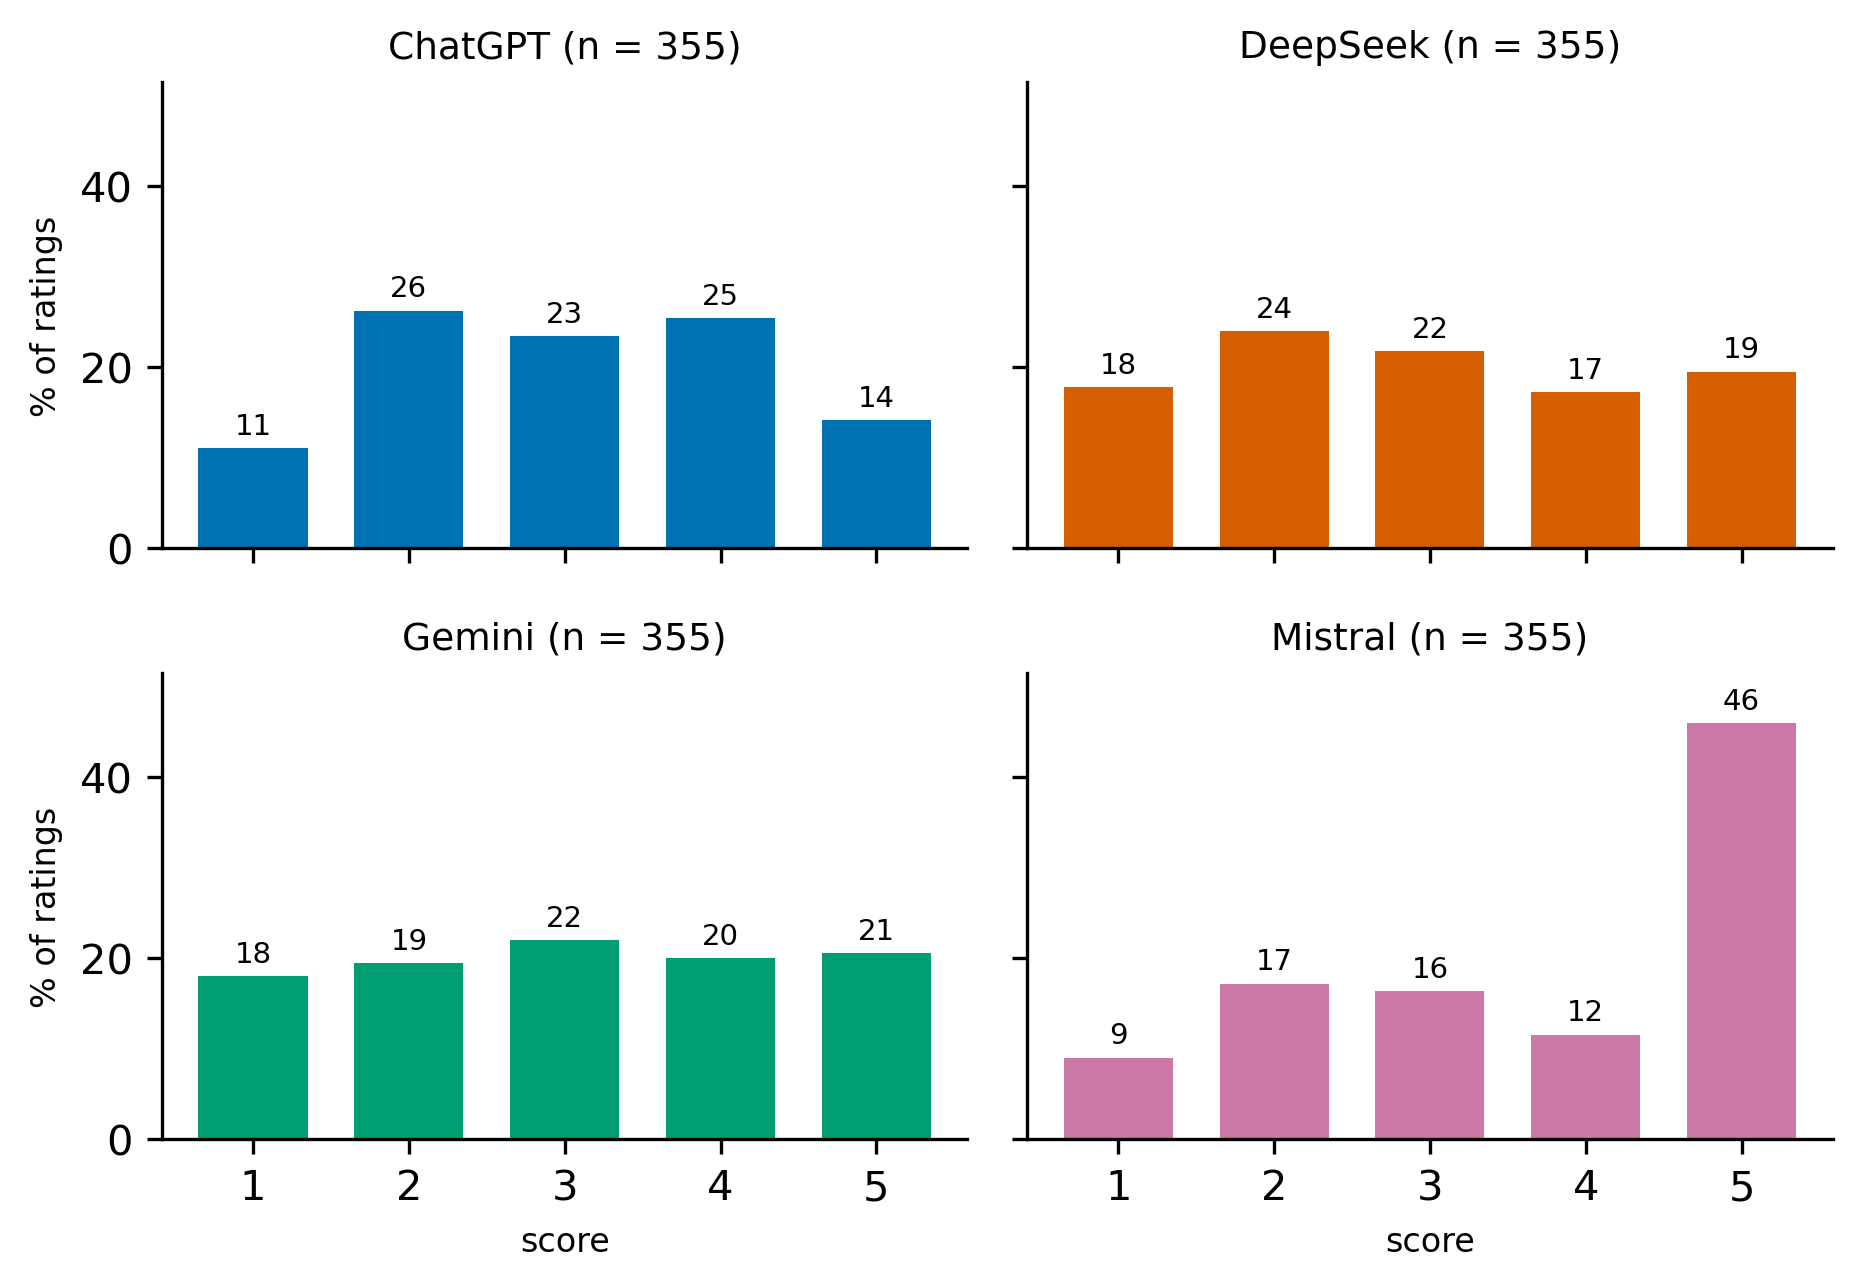

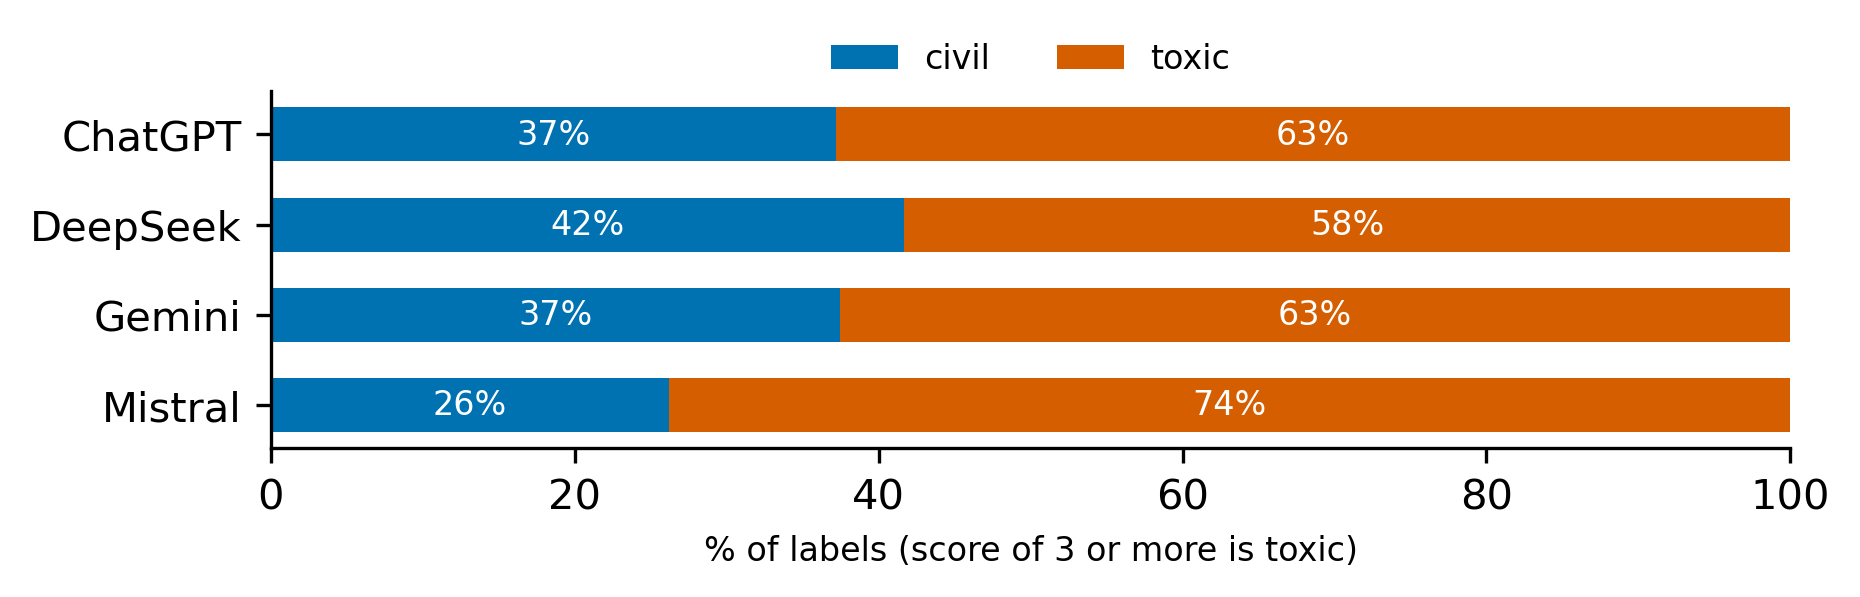

In [2]:
display(Image(filename=MODEL_EDA_DIR / "score_histograms.png", width=600))
display(Image(filename=MODEL_EDA_DIR / "label_shares.png", width=600))

## 7.6 Alignment with the toxic and the civil pole
When the annotator groups split on a text, does the model side with the **toxic pole** (it over-flags) or the **civil pole** (it under-flags), and which group is usually at each pole? On the attributed texts (for Kumar the sample of 65), with the default ratings:

- a **split text** is an attributed text where at least one group is toxic and at least one is civil (texts where all groups hold the same position are not split);
- per characteristic and model: the share of split texts the model labels toxic (bootstrap SD and 2.5-97.5 range, 10,000 resamples, seed 42), and the same per dataset with each distinct text once;
- per group: the share of split texts where it is at the toxic pole, and, per model, how often the model agrees with the group at each pole (cells with fewer than 5 texts are flagged).

Nothing is asked of a model. Written to `new_results/poles/`: `poles_alignment.csv`, `poles_groups.csv`, `poles_direction.csv`, `summary.md`.

In [ ]:
import pandas as pd

from perspective_audit import compute_poles, find_root, load_results, save_poles

if "au_results" not in globals():
    au_results = load_results()
ROOT = find_root()
given = pd.read_csv(ROOT / "new_results" / "aposteriori_for_models.csv", dtype={"item_id": str})
poles = compute_poles(au_results, ROOT / "new_results", given, reps=10_000, seed=42)     # stops if the attributed rows differ from the paper's
save_poles(poles, ROOT / "new_results" / "poles")
poles["alignment"]

## 7.7 Is the attribution rate more than chance? (permutation null)
Characteristics with more groups give smaller groups per text, and small groups pass the unimodality test more easily, so part of the attribution rate (section 7.1) may be chance. For every characteristic we build a **permutation null**:

- on every polarized text with at least four ratings, the group labels are shuffled among the ratings of the **retained groups** (the text's ratings and every group's size on the text stay the same; the 10-text removal rule is not run again);
- the AU test is rerun with the same rules (at least two ratings per group, at least two such groups, every group DFU = 0); the testable texts are the observed ones (asserted); every characteristic is shuffled independently, **1,000 permutations, seed 42** (Kumar: 200 if 1,000 would be too slow);
- per characteristic: the chance rate with its 2.5-97.5 range, the excess over chance, the ratio and p = (1 + permutations with attributed >= observed) / (1 + permutations);
- the **gap**: observed and chance rates of the demographic and non-demographic characteristics, and the excess gap with a bootstrap of the texts (10,000 resamples, seed 42, as in 7.1) in which the chance rates are the mean chance probabilities of the resampled (text, characteristic) pairs;
- the Spearman correlation of the number of groups with the observed and with the chance rate.

The observed rates and the gap are first reproduced from 7.1; the run stops if they differ. Nothing is asked of a model. Written to `new_results/shuffling_robustness/`: `attribution_null_per_characteristic.csv`, `attribution_null_gap.csv`, `per_pair_chance_probability.csv`, `summary.md`.

In [ ]:
from perspective_audit import compute_null, find_root, load_results, save_null

if "au_results" not in globals():
    au_results = load_results()
ROOT = find_root()
null = compute_null(au_results, permutations=1_000, reps=10_000, seed=42)       # stops if Tables 2 and 3 are not reproduced
save_null(null, ROOT / "new_results" / "shuffling_robustness")
null["per_characteristic"]